# Load Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.preprocessing import MinMaxScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

/Users/Jaykay/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


# Load Dataset

In [2]:
mlb_stats = pd.read_csv('/Users/Jaykay/Desktop/INF 397 - Introduction to Machine Learning/Final Project/Data/complete_mlb_stats.csv')

mlb_stats

,Year,Tm,bat_#Bat,bat_BatAge,bat_R/G,bat_G,bat_PA,bat_AB,bat_R,bat_H,...,fld_E,fld_DP,fld_Fld%,fld_Rtot,fld_Rtot/yr,fld_Rdrs,fld_Rdrs/yr,fld_Rgood,Winner,WS_win
0,2015,Arizona Diamondbacks,50.0,26.5,4.44,162.0,6276.0,5649.0,720.0,1494.0,...,86,146,0.986,38.0,3.0,63.0,3.0,9.0,Kansas City Royals,0
1,2015,Atlanta Braves,60.0,28.8,3.54,162.0,6034.0,5420.0,573.0,1361.0,...,90,186,0.985,-16.0,-2.0,-29.0,0.0,-2.0,Kansas City Royals,0
2,2015,Baltimore Orioles,48.0,27.9,4.40,162.0,6007.0,5485.0,713.0,1370.0,...,77,134,0.987,-8.0,-1.0,2.0,0.0,7.0,Kansas City Royals,0
3,2015,Boston Red Sox,51.0,28.2,4.62,162.0,6237.0,5640.0,748.0,1495.0,...,97,148,0.984,-16.0,-2.0,23.0,0.0,-12.0,Kansas City Royals,0
4,2015,Chicago Cubs,50.0,26.9,4.25,162.0,6200.0,5491.0,689.0,1341.0,...,111,120,0.982,1.0,0.0,6.0,2.0,-2.0,Kansas City Royals,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1889,2018,St. Louis Cardinals,49.0,28.0,4.69,162.0,6200.0,5498.0,759.0,1369.0,...,133,151,0.978,-16.0,-1.0,-7.0,-1.0,-1.0,Boston Red Sox,0
1890,2018,Tampa Bay Rays,54.0,27.1,4.42,162.0,6195.0,5475.0,716.0,1415.0,...,85,136,0.986,50.0,5.0,24.0,-1.0,0.0,Boston Red Sox,0
1891,2018,Texas Rangers,50.0,27.4,4.55,162.0,6163.0,5453.0,737.0,1308.0,...,120,168,0.980,18.0,2.0,-37.0,-2.0,-3.0,Boston Red Sox,0
1892,2018,Toronto Blue Jays,63.0,28.9,4.38,162.0,6076.0,5477.0,709.0,1336.0,...,101,138,0.983,-59.0,-6.0,-60.0,0.0,-3.0,Boston Red Sox,0


# EDA - Dataframe Info

In [3]:
## Set pandas display option to show all rows

pd.set_option('display.max_rows', None)

In [4]:
## Check shape of mlb_stats df

mlb_stats.shape

(1894, 85)

In [5]:
## Number of obs per each column and type of data

mlb_stats.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1894 entries, 0 to 1893
Data columns (total 85 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Year         1894 non-null   int64  
 1   Tm           1894 non-null   object 
 2   bat_#Bat     1894 non-null   float64
 3   bat_BatAge   1894 non-null   float64
 4   bat_R/G      1894 non-null   float64
 5   bat_G        1894 non-null   float64
 6   bat_PA       1894 non-null   float64
 7   bat_AB       1894 non-null   float64
 8   bat_R        1894 non-null   float64
 9   bat_H        1894 non-null   float64
 10  bat_2B       1894 non-null   float64
 11  bat_3B       1894 non-null   float64
 12  bat_HR       1894 non-null   float64
 13  bat_RBI      1894 non-null   float64
 14  bat_SB       1894 non-null   float64
 15  bat_CS       1894 non-null   float64
 16  bat_BB       1894 non-null   float64
 17  bat_SO       1894 non-null   float64
 18  bat_BA       1894 non-null   float64
 19  bat_OB

In [6]:
## Statistical summary

mlb_stats.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,1894.0,1991.487856,21.115600,1950.000,1974.0000,1993.000,2010.000,2025.000
bat_#Bat,1894.0,43.082893,7.089943,29.000,38.0000,42.000,47.000,71.000
bat_BatAge,1894.0,28.346568,1.331625,24.600,27.5000,28.300,29.200,33.500
bat_R/G,1894.0,4.416631,0.551553,2.860,4.0400,4.400,4.770,6.670
bat_G,1894.0,158.504752,14.332248,58.000,161.0000,162.000,162.000,165.000
bat_PA,1894.0,6059.008448,566.408621,2011.000,6056.0000,6157.000,6245.000,6554.000
bat_AB,1894.0,5396.987856,503.454622,1752.000,5414.0000,5495.000,5560.000,5781.000
bat_R,1894.0,699.941394,108.226911,219.000,644.0000,704.000,766.750,1027.000
bat_H,1894.0,1388.302534,157.034217,390.000,1342.0000,1404.000,1467.000,1684.000
bat_2B,1894.0,250.613516,46.327340,73.000,220.2500,255.000,283.000,376.000


In [7]:
## Check for missing values

mlb_stats.isnull().sum()

Year              0
Tm                0
bat_#Bat          0
bat_BatAge        0
bat_R/G           0
bat_G             0
bat_PA            0
bat_AB            0
bat_R             0
bat_H             0
bat_2B            0
bat_3B            0
bat_HR            0
bat_RBI           0
bat_SB            0
bat_CS            0
bat_BB            0
bat_SO            0
bat_BA            0
bat_OBP           0
bat_SLG           0
bat_OPS           0
bat_OPS+          0
bat_TB            0
bat_GDP           0
bat_HBP           0
bat_SH            0
bat_SF           64
bat_IBB           0
bat_LOB           0
pit_#P            0
pit_PAge          0
pit_RA/G          0
pit_W             0
pit_L             0
pit_W-L%          0
pit_ERA           0
pit_G             0
pit_GS            0
pit_GF            0
pit_CG            0
pit_tSho          0
pit_cSho          0
pit_SV            0
pit_IP            0
pit_H             0
pit_R             0
pit_ER            0
pit_HR            0
pit_BB            0


In [8]:
## Check for any duplicate rows

duplicate_rows_df = mlb_stats[mlb_stats.duplicated()]
print("number of duplicate rows: ", duplicate_rows_df.shape)

number of duplicate rows:  (0, 85)


# Correlation Matrix

In [9]:
## Drop text columns

mlb_stats_num = mlb_stats.drop(["Year", "Tm", "Winner"], axis = 1)

mlb_stats_num

,bat_#Bat,bat_BatAge,bat_R/G,bat_G,bat_PA,bat_AB,bat_R,bat_H,bat_2B,bat_3B,...,fld_A,fld_E,fld_DP,fld_Fld%,fld_Rtot,fld_Rtot/yr,fld_Rdrs,fld_Rdrs/yr,fld_Rgood,WS_win
0,50.0,26.5,4.44,162.0,6276.0,5649.0,720.0,1494.0,289.0,48.0,...,1697,86,146,0.986,38.0,3.0,63.0,3.0,9.0,0
1,60.0,28.8,3.54,162.0,6034.0,5420.0,573.0,1361.0,251.0,18.0,...,1593,90,186,0.985,-16.0,-2.0,-29.0,0.0,-2.0,0
2,48.0,27.9,4.40,162.0,6007.0,5485.0,713.0,1370.0,246.0,20.0,...,1597,77,134,0.987,-8.0,-1.0,2.0,0.0,7.0,0
3,51.0,28.2,4.62,162.0,6237.0,5640.0,748.0,1495.0,294.0,33.0,...,1625,97,148,0.984,-16.0,-2.0,23.0,0.0,-12.0,0
4,50.0,26.9,4.25,162.0,6200.0,5491.0,689.0,1341.0,272.0,30.0,...,1669,111,120,0.982,1.0,0.0,6.0,2.0,-2.0,0
5,40.0,28.2,3.84,162.0,6070.0,5533.0,622.0,1381.0,260.0,27.0,...,1582,101,159,0.983,-39.0,-4.0,-10.0,0.0,-1.0,0
6,50.0,29.5,3.95,162.0,6196.0,5571.0,640.0,1382.0,257.0,27.0,...,1622,90,131,0.985,0.0,0.0,-12.0,0.0,-4.0,0
7,49.0,28.0,4.16,161.0,6109.0,5439.0,669.0,1395.0,303.0,29.0,...,1528,79,136,0.987,42.0,4.0,9.0,0.0,-3.0,0
8,51.0,28.0,4.55,162.0,6071.0,5572.0,737.0,1479.0,274.0,49.0,...,1818,95,171,0.985,-6.0,-1.0,-27.0,0.0,6.0,0
9,47.0,28.3,4.28,161.0,6159.0,5605.0,689.0,1515.0,289.0,49.0,...,1621,86,165,0.986,-12.0,-1.0,9.0,0.0,-1.0,0


In [10]:
## Calculate matrix of correlations

mlb_corr = mlb_stats_num.corr()
print(mlb_corr)

             bat_#Bat  bat_BatAge   bat_R/G     bat_G    bat_PA    bat_AB  \
bat_#Bat     1.000000    0.056053  0.082069  0.048476  0.016139  0.032970   
bat_BatAge   0.056053    1.000000  0.325271  0.020847  0.083454  0.051096   
bat_R/G      0.082069    0.325271  1.000000 -0.013876  0.142726  0.084365   
bat_G        0.048476    0.020847 -0.013876  1.000000  0.978510  0.986014   
bat_PA       0.016139    0.083454  0.142726  0.978510  1.000000  0.990292   
bat_AB       0.032970    0.051096  0.084365  0.986014  0.990292  1.000000   
bat_R        0.093135    0.278683  0.797633  0.587316  0.701986  0.658884   
bat_H       -0.067178    0.174178  0.408665  0.826783  0.896222  0.894095   
bat_2B       0.307799    0.231378  0.516362  0.536557  0.602775  0.600767   
bat_3B      -0.394130   -0.173207 -0.018117  0.240573  0.259952  0.263007   
bat_HR       0.373459    0.235194  0.655253  0.312802  0.370295  0.351257   
bat_RBI      0.131216    0.292612  0.805963  0.568951  0.682677  0.641147   

In [11]:
## Find correlation higher than 0.8
## Find correlation lower than -0.8

threshold_pos = 0.8
threshold_neg = -0.8

corr_pairs = mlb_corr.unstack().sort_values(ascending = False)

high_corr = corr_pairs[corr_pairs > threshold_pos]
low_corr = corr_pairs[corr_pairs < threshold_neg]

print(high_corr.to_string())

bat_#Bat     bat_#Bat       1.000000
pit_L        pit_L          1.000000
bat_SH       bat_SH         1.000000
bat_SF       bat_SF         1.000000
bat_IBB      bat_IBB        1.000000
bat_LOB      bat_LOB        1.000000
pit_#P       pit_#P         1.000000
pit_PAge     pit_PAge       1.000000
pit_RA/G     pit_RA/G       1.000000
pit_W        pit_W          1.000000
pit_W-L%     pit_W-L%       1.000000
bat_GDP      bat_GDP        1.000000
pit_ERA      pit_ERA        1.000000
pit_G        bat_G          1.000000
             pit_G          1.000000
             pit_GS         1.000000
pit_GS       bat_G          1.000000
             pit_G          1.000000
             pit_GS         1.000000
pit_GF       pit_GF         1.000000
bat_HBP      bat_HBP        1.000000
bat_TB       bat_TB         1.000000
bat_R/G      bat_R/G        1.000000
bat_HR       bat_HR         1.000000
bat_G        pit_G          1.000000
             pit_GS         1.000000
bat_PA       bat_PA         1.000000
b

In [12]:
print(low_corr.to_string())

pit_W-L%  pit_L      -0.848358
pit_L     pit_W-L%   -0.848358
fld_Fld%  fld_E      -0.930927
fld_E     fld_Fld%   -0.930927


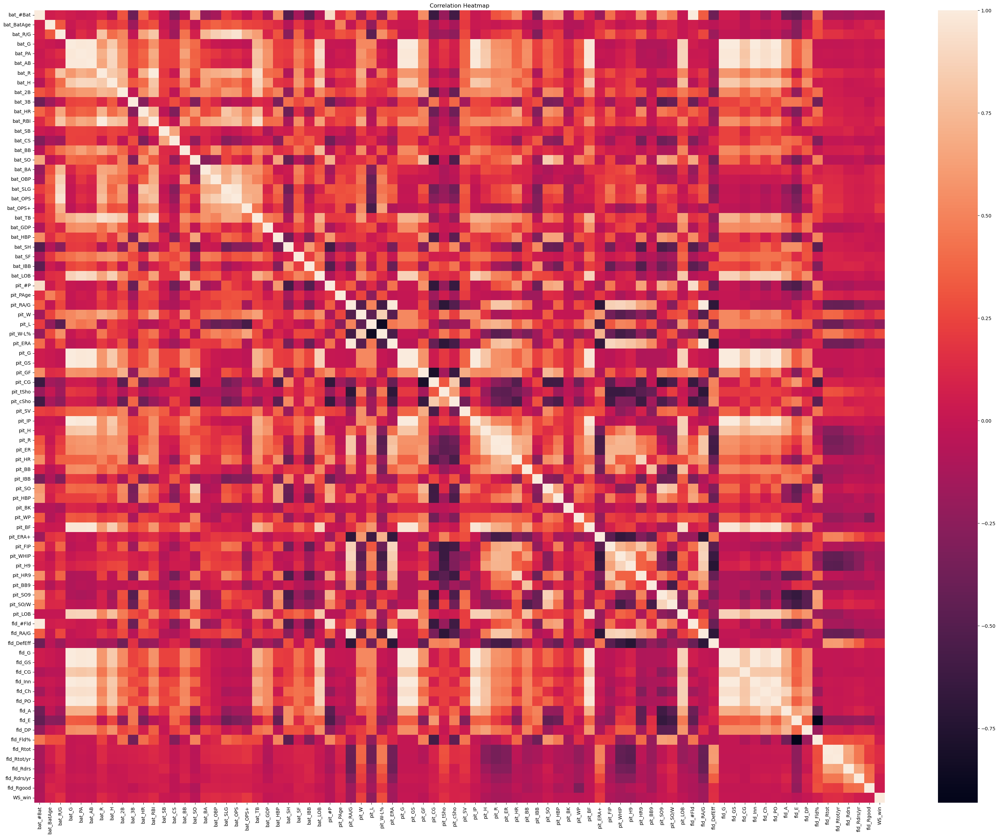

In [13]:
plt.figure(figsize = (40, 30))

sns.heatmap(mlb_stats_num.corr())

plt.title('Correlation Heatmap')

plt.savefig('mlb_heatmap.png', dpi = 300)

plt.show()

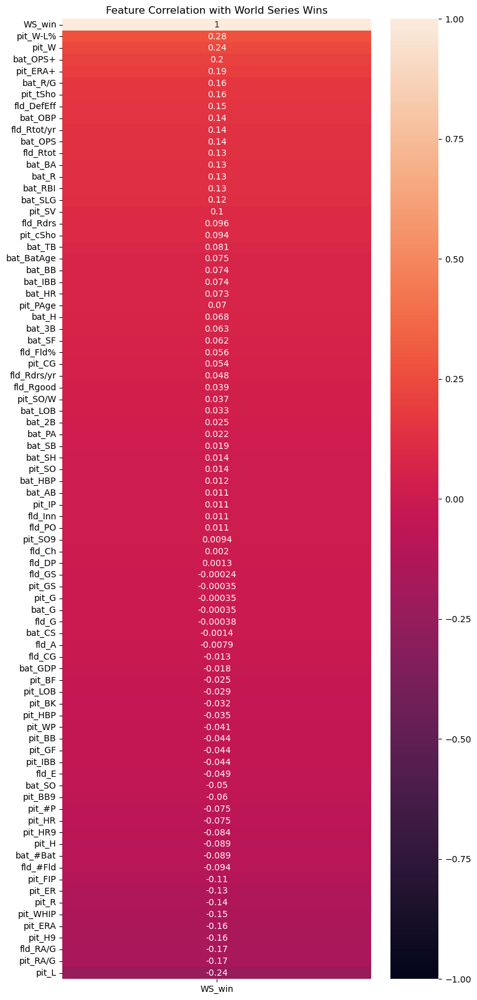

In [14]:
plt.figure(figsize=(8, 20)) 

# Get correlations
target_corr = mlb_stats_num.corr()[['WS_win']].sort_values(by = 'WS_win', ascending = False)

sns.heatmap(target_corr, 
            annot = True, 
            vmin = -1, 
            vmax = 1)

plt.title('Feature Correlation with World Series Wins')
plt.savefig('WS_win_corr.png', dpi = 300)

plt.show()

# VIF

In [15]:
X = mlb_stats_num.copy()
X = X.dropna()

X

,bat_#Bat,bat_BatAge,bat_R/G,bat_G,bat_PA,bat_AB,bat_R,bat_H,bat_2B,bat_3B,...,fld_A,fld_E,fld_DP,fld_Fld%,fld_Rtot,fld_Rtot/yr,fld_Rdrs,fld_Rdrs/yr,fld_Rgood,WS_win
0,50.0,26.5,4.44,162.0,6276.0,5649.0,720.0,1494.0,289.0,48.0,...,1697,86,146,0.986,38.0,3.0,63.0,3.0,9.0,0
1,60.0,28.8,3.54,162.0,6034.0,5420.0,573.0,1361.0,251.0,18.0,...,1593,90,186,0.985,-16.0,-2.0,-29.0,0.0,-2.0,0
2,48.0,27.9,4.40,162.0,6007.0,5485.0,713.0,1370.0,246.0,20.0,...,1597,77,134,0.987,-8.0,-1.0,2.0,0.0,7.0,0
3,51.0,28.2,4.62,162.0,6237.0,5640.0,748.0,1495.0,294.0,33.0,...,1625,97,148,0.984,-16.0,-2.0,23.0,0.0,-12.0,0
4,50.0,26.9,4.25,162.0,6200.0,5491.0,689.0,1341.0,272.0,30.0,...,1669,111,120,0.982,1.0,0.0,6.0,2.0,-2.0,0
5,40.0,28.2,3.84,162.0,6070.0,5533.0,622.0,1381.0,260.0,27.0,...,1582,101,159,0.983,-39.0,-4.0,-10.0,0.0,-1.0,0
6,50.0,29.5,3.95,162.0,6196.0,5571.0,640.0,1382.0,257.0,27.0,...,1622,90,131,0.985,0.0,0.0,-12.0,0.0,-4.0,0
7,49.0,28.0,4.16,161.0,6109.0,5439.0,669.0,1395.0,303.0,29.0,...,1528,79,136,0.987,42.0,4.0,9.0,0.0,-3.0,0
8,51.0,28.0,4.55,162.0,6071.0,5572.0,737.0,1479.0,274.0,49.0,...,1818,95,171,0.985,-6.0,-1.0,-27.0,0.0,6.0,0
9,47.0,28.3,4.28,161.0,6159.0,5605.0,689.0,1515.0,289.0,49.0,...,1621,86,165,0.986,-12.0,-1.0,9.0,0.0,-1.0,0


In [16]:
vif_data = pd.DataFrame()

vif_data["feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]

print(vif_data)

/Users/Jaykay/anaconda3/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:198: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


        feature           VIF
0      bat_#Bat  7.958119e+03
1    bat_BatAge  1.044839e+03
2       bat_R/G  6.065094e+04
3         bat_G           inf
4        bat_PA  1.522053e+07
5        bat_AB  1.104415e+07
6         bat_R  1.069822e+05
7         bat_H           inf
8        bat_2B           inf
9        bat_3B           inf
10       bat_HR           inf
11      bat_RBI  1.553632e+04
12       bat_SB  2.175333e+01
13       bat_CS  4.265455e+01
14       bat_BB  1.004512e+05
15       bat_SO  2.621705e+02
16       bat_BA  1.102828e+05
17      bat_OBP  5.138855e+05
18      bat_SLG  7.944188e+05
19      bat_OPS  2.528886e+06
20     bat_OPS+  2.715491e+03
21       bat_TB           inf
22      bat_GDP  2.482181e+02
23      bat_HBP  1.423303e+03
24       bat_SH  7.302605e+02
25       bat_SF  7.435164e+02
26      bat_IBB  1.687777e+01
27      bat_LOB  7.336707e+04
28       pit_#P  2.035585e+02
29     pit_PAge  8.669236e+02
30     pit_RA/G           inf
31        pit_W  1.190554e+06
32        

In [17]:
vif_data = vif_data.sort_values(by = 'VIF', ascending = False)
vif_data

,feature,VIF
21,bat_TB,inf
10,bat_HR,inf
73,fld_E,inf
70,fld_Ch,inf
30,pit_RA/G,inf
66,fld_G,inf
35,pit_G,inf
36,pit_GS,inf
64,fld_RA/G,inf
9,bat_3B,inf


In [18]:
print(vif_data["VIF"].mean())

inf


# NYY Case Study

EDA of New York Yankees

## Batting Statistics

In [19]:
## Filter batting stats

NYY_bat = (mlb_stats[mlb_stats['Tm'] == 'New York Yankees']
            .filter(regex = '^bat_|^Year')
           .copy()
          )

col_name_bat = NYY_bat.columns

NYY_bat

,Year,bat_#Bat,bat_BatAge,bat_R/G,bat_G,bat_PA,bat_AB,bat_R,bat_H,bat_2B,...,bat_SLG,bat_OPS,bat_OPS+,bat_TB,bat_GDP,bat_HBP,bat_SH,bat_SF,bat_IBB,bat_LOB
18,2015,56.0,31.4,4.72,162.0,6268.0,5567.0,764.0,1397.0,272.0,...,0.421,0.744,102.0,2343.0,105.0,63.0,24.0,54.0,23.0,1151.0
49,2001,47.0,31.2,4.99,161.0,6233.0,5577.0,804.0,1488.0,289.0,...,0.435,0.769,100.0,2426.0,119.0,64.0,30.0,43.0,38.0,1123.0
79,2000,46.0,31.4,5.41,161.0,6311.0,5556.0,871.0,1541.0,294.0,...,0.450,0.804,103.0,2500.0,134.0,57.0,16.0,50.0,42.0,1189.0
108,2014,58.0,32.8,3.91,162.0,6082.0,5497.0,633.0,1349.0,247.0,...,0.380,0.687,94.0,2089.0,111.0,56.0,29.0,47.0,16.0,1098.0
139,2002,38.0,30.0,5.57,161.0,6377.0,5601.0,897.0,1540.0,314.0,...,0.455,0.809,114.0,2547.0,150.0,72.0,23.0,41.0,48.0,1191.0
168,2016,53.0,30.1,4.20,162.0,6059.0,5458.0,680.0,1378.0,245.0,...,0.405,0.720,91.0,2212.0,121.0,42.0,21.0,49.0,19.0,1098.0
198,2017,51.0,28.6,5.30,162.0,6354.0,5594.0,858.0,1463.0,266.0,...,0.447,0.785,105.0,2498.0,119.0,64.0,18.0,56.0,22.0,1184.0
229,2003,49.0,30.4,5.38,163.0,6431.0,5605.0,877.0,1518.0,304.0,...,0.453,0.810,114.0,2540.0,154.0,81.0,25.0,35.0,54.0,1239.0
258,2007,49.0,30.7,5.98,162.0,6528.0,5717.0,968.0,1656.0,326.0,...,0.463,0.829,116.0,2649.0,138.0,78.0,41.0,54.0,32.0,1249.0
288,2013,56.0,31.9,4.01,162.0,6045.0,5449.0,650.0,1321.0,247.0,...,0.376,0.683,88.0,2048.0,121.0,57.0,36.0,36.0,33.0,1064.0


In [21]:
## Scale stats for plotting

scaler = MinMaxScaler(feature_range = (0, 1))

scaled_bat = scaler.fit_transform(NYY_bat)

scaled_batting = pd.DataFrame(scaled_bat, columns = col_name_bat)

# Drop year column
scaled_batting = scaled_batting.drop(columns = ['Year']) 

scaled_batting

,bat_#Bat,bat_BatAge,bat_R/G,bat_G,bat_PA,bat_AB,bat_R,bat_H,bat_2B,bat_3B,...,bat_SLG,bat_OPS,bat_OPS+,bat_TB,bat_GDP,bat_HBP,bat_SH,bat_SF,bat_IBB,bat_LOB
0,0.896552,0.750000,0.546763,0.980769,0.939787,0.960547,0.687596,0.781065,0.770833,0.190476,...,0.601156,0.586957,0.50000,0.791378,0.509434,0.756757,0.247312,0.704918,0.295082,0.855825
1,0.586207,0.716667,0.643885,0.971154,0.931681,0.963177,0.748851,0.857988,0.841667,0.206349,...,0.682081,0.695652,0.43750,0.835551,0.641509,0.770270,0.311828,0.524590,0.540984,0.823529
2,0.551724,0.750000,0.794964,0.971154,0.949745,0.957654,0.851455,0.902790,0.862500,0.285714,...,0.768786,0.847826,0.53125,0.874933,0.783019,0.675676,0.161290,0.639344,0.606557,0.899654
3,0.965517,0.983333,0.255396,0.980769,0.896711,0.942136,0.486983,0.740490,0.666667,0.301587,...,0.364162,0.339130,0.25000,0.656200,0.566038,0.662162,0.301075,0.590164,0.180328,0.794694
4,0.275862,0.516667,0.852518,0.971154,0.965030,0.969490,0.891271,0.901944,0.945833,0.079365,...,0.797688,0.869565,0.87500,0.899947,0.933962,0.878378,0.236559,0.491803,0.704918,0.901961
5,0.793103,0.533333,0.359712,0.980769,0.891385,0.931878,0.558959,0.765004,0.658333,0.206349,...,0.508671,0.482609,0.15625,0.721660,0.660377,0.472973,0.215054,0.622951,0.229508,0.794694
6,0.724138,0.283333,0.755396,0.980769,0.959704,0.967649,0.831547,0.836855,0.745833,0.253968,...,0.751445,0.765217,0.59375,0.873869,0.641509,0.770270,0.182796,0.737705,0.278689,0.893887
7,0.655172,0.583333,0.784173,0.990385,0.977536,0.970542,0.860643,0.883347,0.904167,0.111111,...,0.786127,0.873913,0.87500,0.896221,0.971698,1.000000,0.258065,0.393443,0.803279,0.957324
8,0.655172,0.633333,1.000000,0.980769,1.000000,1.000000,1.000000,1.000000,0.995833,0.396825,...,0.843931,0.956522,0.93750,0.954231,0.820755,0.959459,0.430108,0.704918,0.442623,0.968858
9,0.896552,0.833333,0.291367,0.980769,0.888143,0.929511,0.513017,0.716822,0.666667,0.269841,...,0.341040,0.321739,0.06250,0.634380,0.660377,0.675676,0.376344,0.409836,0.459016,0.755479


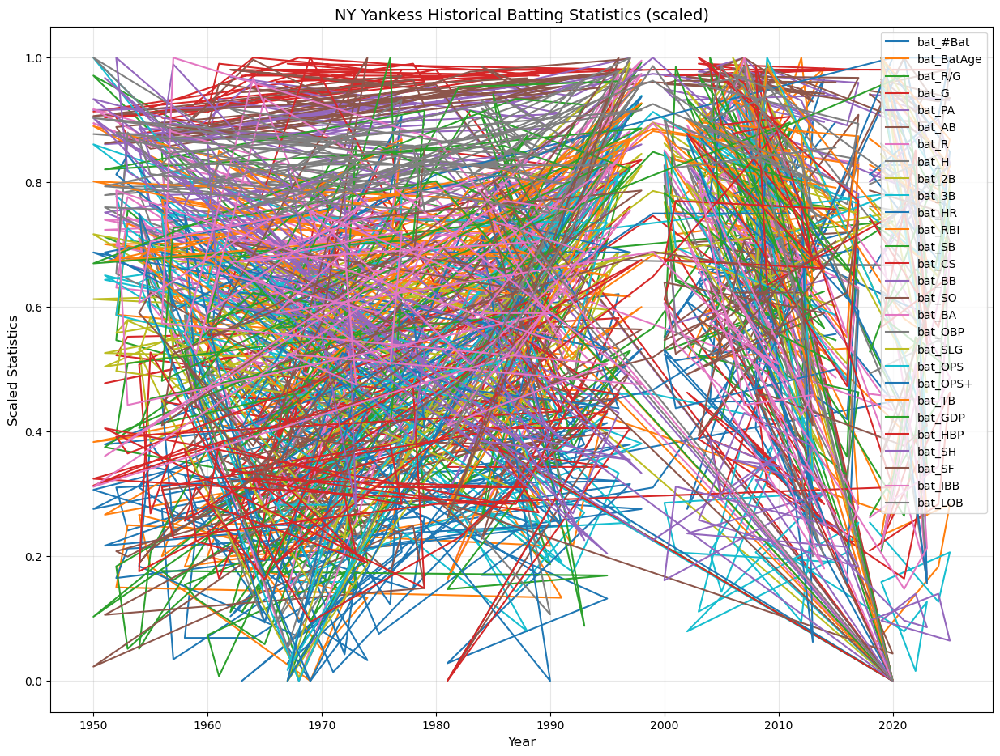

In [22]:
plt.figure(figsize = (15, 11))

for col in scaled_batting.columns:
    
    Year = NYY_bat['Year']
    
    Y = scaled_batting[col].values
    
    plt.plot(Year, 
             Y, 
             label = f'{col}')

plt.title('NY Yankess Historical Batting Statistics (scaled)', fontsize = 14)
plt.xlabel('Year', fontsize = 12)
plt.ylabel('Scaled Statistics', fontsize = 12)
plt.legend(loc = 'upper right')
plt.grid(alpha = 0.3)
plt.show()

## Pitching Statistics

In [23]:
## Filter pitching stats

NYY_pit = (mlb_stats[mlb_stats['Tm'] == 'New York Yankees']
            .filter(regex = '^pit_|^Year')
            .copy()
          )

col_name_pit = NYY_pit.columns

NYY_pit

,Year,pit_#P,pit_PAge,pit_RA/G,pit_W,pit_L,pit_W-L%,pit_ERA,pit_G,pit_GS,...,pit_BF,pit_ERA+,pit_FIP,pit_WHIP,pit_H9,pit_HR9,pit_BB9,pit_SO9,pit_SO/W,pit_LOB
18,2015,33,27.4,4.31,87,75,0.537,4.03,162,162,...,6191,101,3.97,1.297,8.7,1.1,2.9,8.5,2.89,1120
49,2001,20,30.9,4.43,95,65,0.594,4.02,161,161,...,6174,112,3.79,1.305,8.9,1.0,2.9,7.9,2.72,1107
79,2000,22,32.0,5.06,87,74,0.540,4.76,161,161,...,6256,102,4.61,1.429,9.2,1.1,3.6,6.6,1.80,1169
108,2014,33,29.3,4.10,84,78,0.519,3.75,162,162,...,6114,103,3.67,1.232,8.6,1.0,2.5,8.5,3.44,1091
139,2002,17,33.1,4.33,103,58,0.640,3.87,161,161,...,6159,114,3.62,1.270,8.9,0.9,2.5,7.0,2.82,1106
168,2016,29,27.9,4.33,84,78,0.519,4.16,162,162,...,6023,104,4.20,1.262,8.6,1.3,2.8,8.8,3.14,1036
198,2017,25,27.8,4.07,91,71,0.562,3.72,162,162,...,6078,121,3.88,1.209,7.8,1.2,3.1,9.7,3.10,1072
229,2003,23,33.7,4.39,101,61,0.623,4.02,163,163,...,6209,110,3.66,1.291,9.3,0.9,2.3,6.9,2.98,1107
258,2007,28,31.4,4.80,94,68,0.580,4.49,162,162,...,6308,101,4.51,1.431,9.3,0.9,3.6,6.3,1.75,1179
288,2013,24,31.8,4.14,85,77,0.525,3.94,162,162,...,6128,102,3.89,1.305,9.0,1.1,2.7,7.7,2.82,1115


In [24]:
## Scale stats for plotting

scaler = MinMaxScaler(feature_range = (0, 1))

scaled_pit = scaler.fit_transform(NYY_pit)

scaled_pitching = pd.DataFrame(scaled_pit, columns = col_name_pit)

# Drop year column
scaled_pitching = scaled_pitching.drop(columns = ['Year']) 

scaled_pitching

,pit_#P,pit_PAge,pit_RA/G,pit_W,pit_L,pit_W-L%,pit_ERA,pit_G,pit_GS,pit_GF,...,pit_BF,pit_ERA+,pit_FIP,pit_WHIP,pit_H9,pit_HR9,pit_BB9,pit_SO9,pit_SO/W,pit_LOB
0,0.875000,0.128205,0.594595,0.666667,0.705882,0.424138,0.629442,0.980769,0.980769,0.971154,...,0.971976,0.394737,0.583333,0.497238,0.538462,0.555556,0.260870,0.737705,0.773663,0.911192
1,0.333333,0.576923,0.659459,0.765432,0.558824,0.620690,0.624365,0.971154,0.971154,0.923077,...,0.967904,0.684211,0.467949,0.519337,0.615385,0.444444,0.260870,0.639344,0.703704,0.895377
2,0.416667,0.717949,1.000000,0.666667,0.691176,0.434483,1.000000,0.971154,0.971154,0.903846,...,0.987545,0.421053,0.993590,0.861878,0.730769,0.555556,0.565217,0.426230,0.325103,0.970803
3,0.875000,0.371795,0.481081,0.629630,0.750000,0.362069,0.487310,0.980769,0.980769,0.951923,...,0.953533,0.447368,0.391026,0.317680,0.500000,0.444444,0.086957,0.737705,1.000000,0.875912
4,0.208333,0.858974,0.605405,0.864198,0.455882,0.779310,0.548223,0.971154,0.971154,0.903846,...,0.964311,0.736842,0.358974,0.422652,0.615385,0.333333,0.086957,0.491803,0.744856,0.894161
5,0.708333,0.192308,0.605405,0.629630,0.750000,0.362069,0.695431,0.980769,0.980769,1.000000,...,0.931737,0.473684,0.730769,0.400552,0.500000,0.777778,0.217391,0.786885,0.876543,0.809002
6,0.541667,0.179487,0.464865,0.716049,0.647059,0.510345,0.472081,0.980769,0.980769,0.980769,...,0.944910,0.921053,0.525641,0.254144,0.192308,0.666667,0.347826,0.934426,0.860082,0.852798
7,0.458333,0.935897,0.637838,0.839506,0.500000,0.720690,0.624365,0.990385,0.990385,0.932692,...,0.976287,0.631579,0.384615,0.480663,0.769231,0.333333,0.000000,0.475410,0.810700,0.895377
8,0.666667,0.641026,0.859459,0.753086,0.602941,0.572414,0.862944,0.980769,0.980769,0.990385,...,1.000000,0.394737,0.929487,0.867403,0.769231,0.333333,0.565217,0.377049,0.304527,0.982968
9,0.500000,0.692308,0.502703,0.641975,0.735294,0.382759,0.583756,0.980769,0.980769,0.932692,...,0.956886,0.421053,0.532051,0.519337,0.653846,0.555556,0.173913,0.606557,0.744856,0.905109


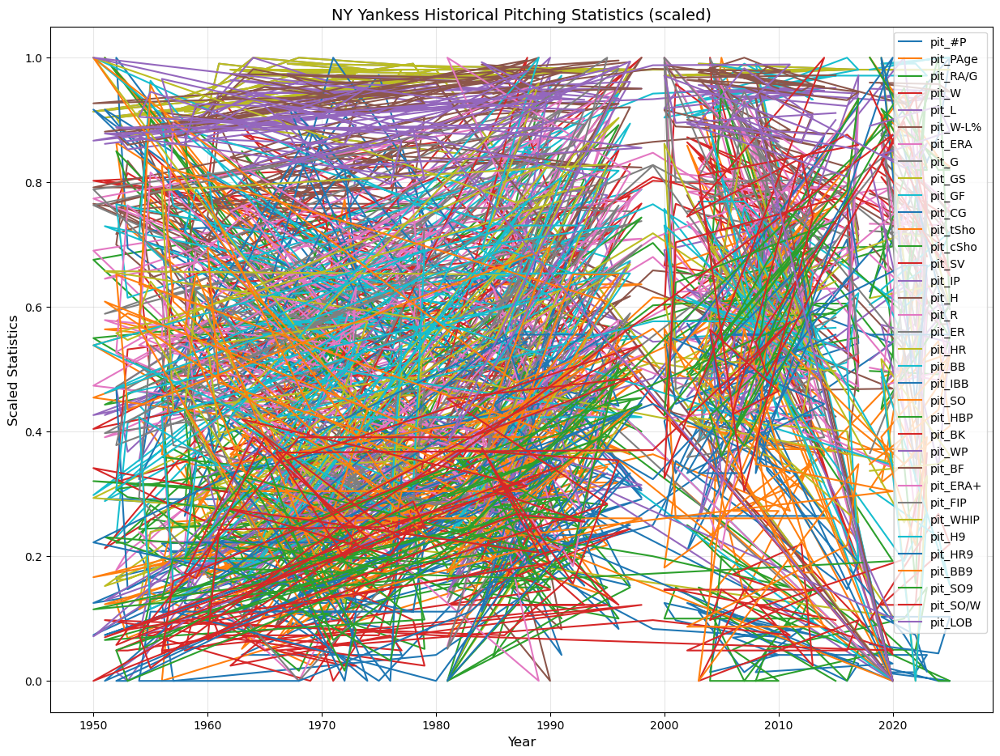

In [25]:
plt.figure(figsize = (15, 11))

for col in scaled_pitching.columns:
    
    Year = NYY_pit['Year']
    
    Y = scaled_pitching[col].values
    
    plt.plot(Year, 
             Y, 
             label = f'{col}')

plt.title('NY Yankess Historical Pitching Statistics (scaled)', fontsize = 14)
plt.xlabel('Year', fontsize = 12)
plt.ylabel('Scaled Statistics', fontsize = 12)
plt.legend(loc = 'upper right')
plt.grid(alpha = 0.3)
plt.show()

## Fielding Statistics

In [26]:
## Filter fielding stats

NYY_fld = (
    mlb_stats[mlb_stats['Tm'] == 'New York Yankees']
    .filter(regex = '^fld_|^Year')
    .copy()
)

col_name = NYY_fld.columns

NYY_fld

,Year,fld_#Fld,fld_RA/G,fld_DefEff,fld_G,fld_GS,fld_CG,fld_Inn,fld_Ch,fld_PO,fld_A,fld_E,fld_DP,fld_Fld%,fld_Rtot,fld_Rtot/yr,fld_Rdrs,fld_Rdrs/yr,fld_Rgood
18,2015,55,4.31,0.685,162,1458,1037,13119.0,6060,4373,1594,93,135,0.985,-29.0,-3.0,-32.0,-2.0,-7.0
49,2001,45,4.43,0.683,161,1449,1133,13062.0,5992,4354,1529,109,132,0.982,-57.0,-5.0,NaN,NaN,NaN
79,2000,46,5.06,0.693,161,1449,1068,12819.0,5869,4273,1487,109,132,0.981,-22.0,-2.0,NaN,NaN,NaN
108,2014,58,4.10,0.687,162,1458,1120,13077.0,5925,4359,1474,92,107,0.984,-14.0,-1.0,-6.0,0.0,-3.0
139,2002,37,4.33,0.688,161,1449,1145,13068.0,6007,4356,1524,127,117,0.979,-56.0,-5.0,NaN,NaN,NaN
168,2016,53,4.33,0.694,162,1458,1109,12855.0,5907,4285,1536,86,116,0.985,4.0,0.0,-3.0,-2.0,-4.0
198,2017,51,4.07,0.703,162,1458,1131,13038.0,5909,4346,1468,95,102,0.984,29.0,3.0,20.0,-1.0,-12.0
229,2003,49,4.39,0.681,163,1467,1194,13158.0,6078,4386,1578,114,126,0.981,-66.0,-6.0,-55.0,-1.0,NaN
258,2007,49,4.80,0.689,162,1458,1099,13056.0,6028,4352,1588,88,174,0.985,9.0,1.0,-19.0,-1.0,-5.0
288,2013,55,4.14,0.687,162,1458,1128,13026.0,5955,4342,1544,69,139,0.988,-22.0,-2.0,9.0,-1.0,-2.0


In [27]:
## Scale stats for plotting

scaler = MinMaxScaler(feature_range = (0, 1))

scaled_fld = scaler.fit_transform(NYY_fld)

scaled_fielding = pd.DataFrame(scaled_fld, columns = col_name)

# Drop year column
scaled_fielding = scaled_fielding.drop(columns = ['Year']) 

scaled_fielding

,fld_#Fld,fld_RA/G,fld_DefEff,fld_G,fld_GS,fld_CG,fld_Inn,fld_Ch,fld_PO,fld_A,fld_E,fld_DP,fld_Fld%,fld_Rtot,fld_Rtot/yr,fld_Rdrs,fld_Rdrs/yr,fld_Rgood
0,0.862069,0.594595,0.076923,0.980769,0.980769,0.740363,0.951292,0.895542,0.952871,0.742555,0.416667,0.553672,0.769231,0.251497,0.200000,0.527076,0.000000,0.217391
1,0.517241,0.659459,0.038462,0.971154,0.971154,0.849206,0.944997,0.880461,0.946565,0.699537,0.564815,0.536723,0.538462,0.083832,0.066667,NaN,NaN,NaN
2,0.551724,1.000000,0.230769,0.971154,0.971154,0.775510,0.918158,0.853183,0.919681,0.671741,0.564815,0.536723,0.461538,0.293413,0.266667,NaN,NaN,NaN
3,0.965517,0.481081,0.115385,0.980769,0.980769,0.834467,0.946653,0.865602,0.948224,0.663137,0.407407,0.395480,0.692308,0.341317,0.333333,0.620939,0.666667,0.391304
4,0.241379,0.605405,0.134615,0.971154,0.971154,0.862812,0.945659,0.883788,0.947229,0.696228,0.731481,0.451977,0.307692,0.089820,0.066667,NaN,NaN,NaN
5,0.793103,0.605405,0.250000,0.980769,0.980769,0.821995,0.922134,0.861610,0.923664,0.704169,0.351852,0.446328,0.769231,0.449102,0.400000,0.631769,0.000000,0.347826
6,0.724138,0.464865,0.423077,0.980769,0.980769,0.846939,0.942346,0.862054,0.943910,0.659166,0.435185,0.367232,0.692308,0.598802,0.600000,0.714801,0.333333,0.000000
7,0.655172,0.637838,0.000000,0.990385,0.990385,0.918367,0.955600,0.899534,0.957186,0.731966,0.611111,0.502825,0.461538,0.029940,0.000000,0.444043,0.333333,NaN
8,0.655172,0.859459,0.153846,0.980769,0.980769,0.810658,0.944334,0.888445,0.945901,0.738584,0.370370,0.774011,0.769231,0.479042,0.466667,0.574007,0.333333,0.304348
9,0.862069,0.502703,0.115385,0.980769,0.980769,0.843537,0.941021,0.872255,0.942582,0.709464,0.194444,0.576271,1.000000,0.293413,0.266667,0.675090,0.333333,0.434783


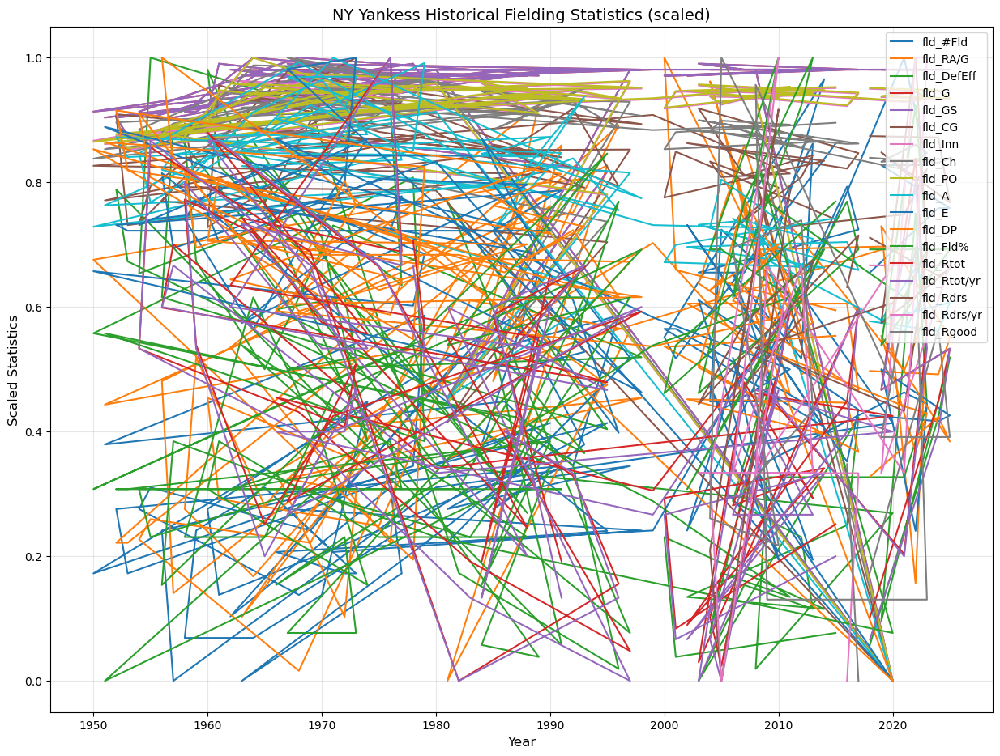

In [28]:
plt.figure(figsize = (15, 11))

for col in scaled_fielding.columns:
    
    Year = NYY_fld['Year']
    
    Y = scaled_fielding[col].values
    
    plt.plot(Year, 
             Y, 
             label = f'{col}')

plt.title('NY Yankess Historical Fielding Statistics (scaled)', fontsize = 14)
plt.xlabel('Year', fontsize = 12)
plt.ylabel('Scaled Statistics', fontsize = 12)
plt.legend(loc = 'upper right')
plt.grid(alpha = 0.3)
plt.show()